# 01 · Apartments near a subway station in Buenos Aires

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/oechenique/analytics/blob/main/notebooks/01_caba_subway_apartments.ipynb)

**The question** (from the 2023 version of this repo): the city will open a gastronomic hub near **Congreso de Tucumán**, the last station of subway line D, and a manager wants to know how many apartments for sale there are **within 800 m** of the station.

This notebook answers it twice:

1. **800 m as the crow flies**: a real 800 m circle, drawn in a projected CRS (POSGAR 2007 / Argentina 5, EPSG:5347). The 2023 version buffered `0.0072°` in latitude/longitude, which in Buenos Aires is an ellipse (~800 m north–south, ~660 m east–west).
2. **800 m on foot**: the distance along the street network from OpenStreetMap, which is what "800 m from the station" means for someone walking (about 10 minutes).

Data: a Properati export of sale listings (in this repo, `data/real_estate_data.zip`), the city boundary from Buenos Aires Data and the walking network from OpenStreetMap.

## Setup

In [1]:
# Colab already ships pandas, geopandas, shapely and matplotlib; install only what is missing.
# Locally, use requirements.txt instead.
import sys

if "google.colab" in sys.modules:
    %pip install -q osmnx==2.1.1 pooch==1.9.0

In [2]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import osmnx as ox
import pandas as pd
import pooch
from matplotlib.lines import Line2D
from shapely import concave_hull

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
IMG_DIR = ROOT / "docs" / "img"
IMG_DIR.mkdir(parents=True, exist_ok=True)

CRS_M = 5347  # POSGAR 2007 / Argentina 5: metres, central meridian 60°W
RADIUS_M = 800
STATION = "Congreso de Tucumán"
STATION_HINT = (-34.5553, -58.4625)  # only to search OSM around it; the exact point comes from OSM

ox.settings.use_cache = True
ox.settings.cache_folder = str(DATA_DIR / "osmnx_cache")

## 1. Listings

The zip is in the repo. When the notebook runs without the repo (Colab), it downloads the same file from GitHub and checks its SHA-256.

In [3]:
ZIP = DATA_DIR / "real_estate_data.zip"
if not ZIP.exists():
    ZIP = Path(pooch.retrieve(
        "https://github.com/oechenique/analytics/raw/main/data/real_estate_data.zip",
        known_hash="sha256:fcff5c4f3c087a82af0ba5b9423113cb3f260c3dc567181638d46417a572a247",
        path=DATA_DIR,
        fname="real_estate_data.zip",
    ))

cols = ["property_type", "state_name", "place_name", "lat", "lon", "price_usd_per_m2"]
listings = pd.read_csv(ZIP, usecols=cols)
caba = listings[listings["state_name"] == "Capital Federal"]
apts = caba[caba["property_type"] == "apartment"].dropna(subset=["lat", "lon"])
print(f"Listings in the file: {len(listings):,}")
print(f"Capital Federal: {len(caba):,}, apartments: {(caba['property_type'] == 'apartment').sum():,}, "
      f"apartments with coordinates: {len(apts):,}")

Listings in the file: 121,220
Capital Federal: 32,316, apartments: 27,037, apartments with coordinates: 19,446


Some coordinates fall outside the city (geocoding errors), so the points are clipped to the city boundary.

In [4]:
BARRIOS_URL = "https://cdn.buenosaires.gob.ar/datosabiertos/datasets/ministerio-de-educacion/barrios/barrios.geojson"
barrios = gpd.read_file(pooch.retrieve(BARRIOS_URL, known_hash=None, path=DATA_DIR, fname="barrios.geojson"))
city = barrios.to_crs(CRS_M).dissolve()

pts = gpd.GeoDataFrame(apts, geometry=gpd.points_from_xy(apts["lon"], apts["lat"]), crs=4326).to_crs(CRS_M)
pts = pts[pts.within(city.geometry.iloc[0])].copy()
print(f"Apartments inside the city boundary: {len(pts):,}")

Apartments inside the city boundary: 19,418


## 2. The station and the walking network

In [5]:
stations = ox.features_from_point(STATION_HINT, tags={"railway": "station"}, dist=600)
station = stations[stations["name"].str.contains(STATION, na=False)].to_crs(CRS_M)
station_pt = station.geometry.iloc[0].centroid
station_ll = gpd.GeoSeries([station_pt], crs=CRS_M).to_crs(4326).iloc[0]
print(station[["name"]].to_string(), f"\n→ {station_ll.y:.5f}, {station_ll.x:.5f}")

# Walking network only around the station: 1.5 km covers everything reachable within 800 m
G = ox.graph_from_point((station_ll.y, station_ll.x), dist=1500, network_type="walk")
G = ox.project_graph(G, to_crs=f"EPSG:{CRS_M}")
nodes, edges = ox.graph_to_gdfs(G)
print(f"Walking graph: {len(nodes):,} nodes, {len(edges):,} edges")

                                   name
element id                             
node    3475506076  Congreso de Tucumán 
→ -34.55580, -58.46222


Walking graph: 2,384 nodes, 7,122 edges


## 3. Circle vs. walk

- **Circle**: points within 800 m of the station in a straight line.
- **Walk**: network distance from the station's nearest node to each apartment's nearest node, plus the straight-line hops from the station and from the apartment to those nodes.
- **2023 ellipse**: the original `0.0072°` buffer, for comparison.

In [6]:
circle = station_pt.buffer(RADIUS_M)
ellipse_2023 = gpd.GeoSeries([station_ll.buffer(0.007199294469)], crs=4326).to_crs(CRS_M).iloc[0]

near = pts[pts.distance(station_pt) <= 1500].copy()  # the graph covers 1.5 km
src = ox.distance.nearest_nodes(G, station_pt.x, station_pt.y)
src_hop = station_pt.distance(nodes.geometry[src])
dist_from_station = nx.single_source_dijkstra_path_length(G, src, cutoff=RADIUS_M, weight="length")

near["node"] = ox.distance.nearest_nodes(G, near.geometry.x, near.geometry.y)
near["hop"] = near.geometry.distance(nodes.geometry.loc[near["node"]].set_axis(near.index))
near["walk_m"] = near["node"].map(dist_from_station) + near["hop"] + src_hop
near["in_circle"] = near.within(circle)
near["in_walk"] = near["walk_m"] <= RADIUS_M
near["in_ellipse_2023"] = near.within(ellipse_2023)

reach = nodes.loc[[n for n, d in dist_from_station.items() if d + src_hop <= RADIUS_M]]
walk_area = concave_hull(reach.geometry.union_all(), ratio=0.2)

summary = pd.DataFrame({
    area: {
        "apartments": int(near[col].sum()),
        "median USD/m²": near.loc[near[col], "price_usd_per_m2"].median(),
        "area (ha)": geom.area / 1e4,
    }
    for area, col, geom in [
        ("2023 ellipse (0.0072°)", "in_ellipse_2023", ellipse_2023),
        ("800 m circle", "in_circle", circle),
        ("800 m walk", "in_walk", walk_area),
    ]
}).T
summary["apartments"] = summary["apartments"].astype(int)
summary.round(0)

,apartments,median USD/m²,area (ha)
2023 ellipse (0.0072°),470,2694.0,166.0
800 m circle,535,2744.0,201.0
800 m walk,316,2719.0,95.0


In [7]:
both = (near["in_circle"] & near["in_walk"]).sum()
only_circle = (near["in_circle"] & ~near["in_walk"]).sum()
print(f"In the circle and within an 800 m walk: {both}")
print(f"In the circle but more than 800 m away on foot: {only_circle} "
      f"({only_circle / near['in_circle'].sum():.0%} of the circle)")
print(f"Walking detour factor (median walk / straight line, inside the circle): "
      f"{(near.loc[near['in_circle'] & near['walk_m'].notna(), 'walk_m'] / near.loc[near['in_circle'] & near['walk_m'].notna()].distance(station_pt)).median():.2f}")

In the circle and within an 800 m walk: 316
In the circle but more than 800 m away on foot: 219 (41% of the circle)
Walking detour factor (median walk / straight line, inside the circle): 1.39


## 4. Map

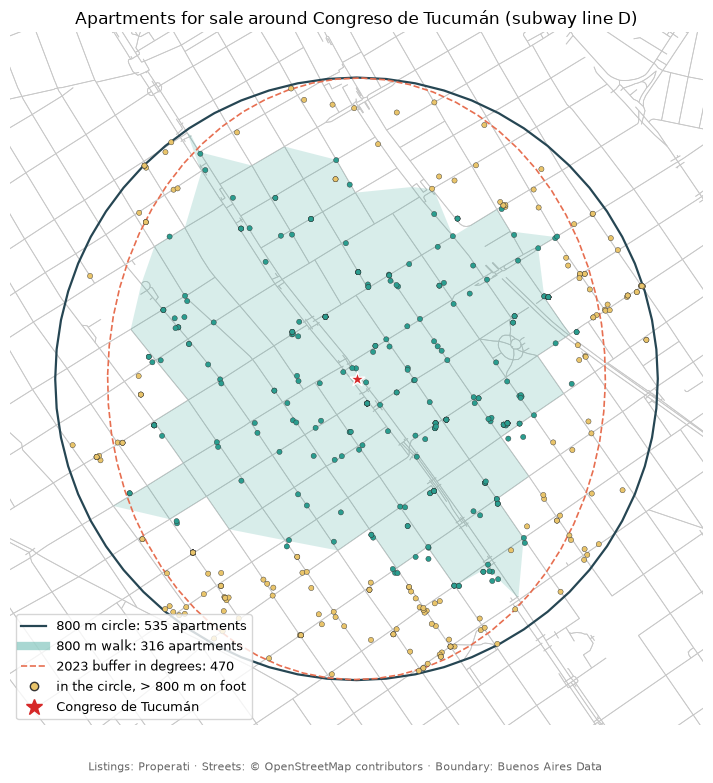

In [8]:
fig, ax = plt.subplots(figsize=(9, 9))
edges.plot(ax=ax, color="#c8c8c8", linewidth=0.6, zorder=1)
gpd.GeoSeries([walk_area], crs=CRS_M).plot(ax=ax, color="#2a9d8f", alpha=0.18, zorder=2)
gpd.GeoSeries([circle], crs=CRS_M).boundary.plot(ax=ax, color="#264653", linewidth=1.6, zorder=3)
gpd.GeoSeries([ellipse_2023], crs=CRS_M).boundary.plot(ax=ax, color="#e76f51", linewidth=1.2,
                                                       linestyle="--", zorder=3)

inside = near[near["in_circle"] | near["in_walk"]]
colors = np.where(inside["in_walk"], "#2a9d8f", "#e9c46a")
ax.scatter(inside.geometry.x, inside.geometry.y, s=14, c=colors, edgecolor="#333", linewidth=0.3, zorder=4)
ax.scatter(station_pt.x, station_pt.y, s=120, marker="*", color="#d62828", edgecolor="white", zorder=5)

pad = RADIUS_M * 1.15
ax.set_xlim(station_pt.x - pad, station_pt.x + pad)
ax.set_ylim(station_pt.y - pad, station_pt.y + pad)
ax.set_axis_off()
ax.legend(handles=[
    Line2D([], [], color="#264653", lw=1.6, label=f"800 m circle: {near['in_circle'].sum()} apartments"),
    Line2D([], [], color="#2a9d8f", lw=6, alpha=0.4, label=f"800 m walk: {near['in_walk'].sum()} apartments"),
    Line2D([], [], color="#e76f51", lw=1.2, ls="--", label=f"2023 buffer in degrees: {near['in_ellipse_2023'].sum()}"),
    Line2D([], [], marker="o", ls="", color="#e9c46a", mec="#333", label="in the circle, > 800 m on foot"),
    Line2D([], [], marker="*", ls="", color="#d62828", ms=12, label=STATION),
], loc="lower left", frameon=True, fontsize=9)
ax.set_title(f"Apartments for sale around {STATION} (subway line D)", fontsize=12)
fig.text(0.5, 0.06, "Listings: Properati · Streets: © OpenStreetMap contributors · Boundary: Buenos Aires Data",
         ha="center", fontsize=8, color="#666")
fig.savefig(IMG_DIR / "congreso_walk_vs_circle.png", dpi=130, bbox_inches="tight")
plt.show()

## Takeaways

- Buffering in degrees is the classic bug: at 34.6°S a degree of longitude is ~18 % shorter than a degree of latitude, so the 2023 "800 m" area was an ellipse. Always buffer in a projected CRS in metres (EPSG:5347 for Buenos Aires, or the local UTM zone).
- A circle is an upper bound for "how close": the street grid, the rail tracks and the blocks without through streets make some points in the circle more than 800 m away on foot.
- Limits: listings are not geocoded precisely (some share the same point), there are no listing dates in the file, and asking prices are not sale prices.